# 06b · Optional: DCRNN-style comparison

> **Optional extension.** It does not affect the primary results (notebooks 04-07 stand without it). If this notebook is not run, notebook 07 simply reports DCRNN as *not available*.

**Objective.** Add a second graph-based model from the literature, the **Diffusion Convolutional Recurrent Neural Network** (DCRNN, Li et al., ICLR 2018), as a point of comparison for the ST-GAT.

**What this is, and is not.**
* The original implementation is TensorFlow 1 code with obsolete dependencies; installing it into this environment would break the project's modern stack. Instead, `src/dcrnn_model.py` is a **clean PyTorch re-implementation of the idea**: a sequence-to-sequence model whose GRU cells use *diffusion convolutions* over the directed road graph (forward and backward random walks).
* It is **not a port** and has **not been verified to be numerically equivalent** to the original. We make no claim about reproducing the published numbers.
* Differences (documented in the module): plain powers of the random-walk matrices; the decoder starts from the same anchor (last observed speed) and predicts residuals like our other learned models; calendar features of the target time as decoder input; a smaller training budget (stride-3 training windows, at most 30 epochs, linear teacher-forcing decay).

**Methodology.** Same data, split, scaler, windows, masked-MAE loss, validation early stopping and evaluation as the ST-GAT. Only the model differs.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../traffic-flow-control  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, gat_model as gm, dcrnn_model as dm, evaluation as ev, visualization as viz
from src.metrics import compute_metrics

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
device = gm.select_device()
RETRAIN = False                    # True: retrain from scratch (about 25 min on an Apple M3); False: reload the saved checkpoint if it exists
params = dict(config.DCRNN_PARAMS)
print("device:", device, "| hyper-parameters:", params)

device: mps | hyper-parameters: {'hidden': 64, 'n_layers': 2, 'k_hops': 2, 'batch_size': 16, 'lr': 0.002, 'weight_decay': 1e-05, 'max_epochs': 30, 'patience': 6, 'grad_clip': 5.0, 'train_stride': 3, 'train_origin_limit': None, 'seed': 42}


## 1 · Diffusion supports from the directed graph

Forward walk `D_O^-1 W` (where traffic goes next) and backward walk `D_I^-1 W^T` (where it came from). Self-loops are removed from `W`; a sensor without out- (or in-) edges has an all-zero row, so it only keeps its own state.

In [3]:
fwd, bwd = dm.random_walk_supports(graph.adjacency)
for name, s in (("forward  D_O^-1 W", fwd), ("backward D_I^-1 W^T", bwd)):
    sums = s.sum(1)
    print(f"{name}: shape {s.shape}, rows summing to 1: {int(np.isclose(sums, 1).sum())}, all-zero rows: {int((sums == 0).sum())}, non-zeros {int((s > 0).sum())}")
    assert np.isfinite(s).all() and set(np.round(sums[sums > 0], 5)) == {1.0}

forward  D_O^-1 W: shape (207, 207), rows summing to 1: 202, all-zero rows: 5, non-zeros 1515
backward D_I^-1 W^T: shape (207, 207), rows summing to 1: 205, all-zero rows: 2, non-zeros 1515


## 2 · Model, tensors and training data

In [4]:
data = gm.GraphData(speed=ctx.speed, mask=ctx.mask, values_scaled=pp.fill_for_model(ctx.speed, ctx.mask, ctx.scaler), time_feats=pp.time_feature_matrix(ctx.timestamps),
                    locf_value=ctx.locf_value, locf_age=ctx.locf_age, scaler=ctx.scaler)
train_origins = pp.evenly_spaced(ctx.origins["train"][::params["train_stride"]], params["train_origin_limit"])
val_origins, test_origins = ctx.origins["val"], ctx.origins["test"]
gm.set_seed(params["seed"])
model = dm.DCRNN(graph.adjacency, in_features=6, hidden=params["hidden"], n_layers=params["n_layers"], k_hops=params["k_hops"])
print(f"parameters: {gm.count_parameters(model):,} | training origins used: {len(train_origins):,} (of {len(ctx.origins['train']):,}) | validation origins: {len(val_origins):,}")

x, anchor, y, valid = data.batch(train_origins[:2], torch.device("cpu"))
dec = dm.decoder_features(data, train_origins[:2], torch.device("cpu"))
model.eval()
with torch.no_grad():
    out = model(x, anchor, dec)
print(f"encoder input {tuple(x.shape)}, decoder calendar features {tuple(dec.shape)} -> prediction {tuple(out.shape)} = [batch, 12 steps, 207 sensors] (scaled)")
assert out.shape == (2, 12, N) and torch.isfinite(out).all()

parameters: 380,033 | training origins used: 7,961 (of 23,881) | validation origins: 3,445
encoder input (2, 12, 207, 6), decoder calendar features (2, 12, 207, 4) -> prediction (2, 12, 207) = [batch, 12 steps, 207 sensors] (scaled)


## 3 · Training (masked MAE; validation early stopping; test untouched)

> **Provenance of the delivered run.** The model was trained once in an earlier execution (up to 30 epochs of ~2 minutes each on an Apple M3, patience 6; training is deterministic). With `RETRAIN = False`, as delivered, the saved checkpoint is reloaded and its original training log is printed; forecasts and scores are recomputed. Whether training ended by early stopping or by the epoch limit is printed in the training log below.

epoch   1 | train MAE(scaled) 0.2376 | val MAE 3.4416 mph | tf 0.50 | 122s  *


epoch   2 | train MAE(scaled) 0.2043 | val MAE 3.3215 mph | tf 0.47 | 128s  *


epoch   3 | train MAE(scaled) 0.2030 | val MAE 3.2622 mph | tf 0.44 | 131s  *


epoch   4 | train MAE(scaled) 0.2014 | val MAE 3.1274 mph | tf 0.42 | 127s  *


epoch   5 | train MAE(scaled) 0.2001 | val MAE 3.1370 mph | tf 0.39 | 130s


epoch   6 | train MAE(scaled) 0.1994 | val MAE 3.0298 mph | tf 0.36 | 131s  *


... (20 outputs left out)

epoch  27 | train MAE(scaled) 0.2211 | val MAE 2.8367 mph | tf 0.00 | 124s  *


epoch  28 | train MAE(scaled) 0.2200 | val MAE 2.8463 mph | tf 0.00 | 124s


epoch  29 | train MAE(scaled) 0.2191 | val MAE 2.8417 mph | tf 0.00 | 130s


epoch  30 | train MAE(scaled) 0.2191 | val MAE 2.8458 mph | tf 0.00 | 129s
DCRNN-style model: best epoch 27 | best validation MAE 2.837 mph | 65.9 min


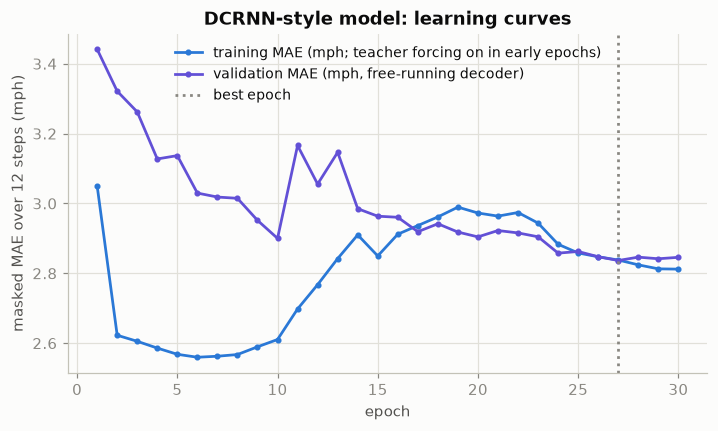

In [5]:
ckpt = config.MODELS_DIR / f"{config.tagged('dcrnn')}.pt"
hist_path = config.METRICS_DIR / f"{config.tagged('dcrnn')}_history.json"
log_path = config.METRICS_DIR / f"{config.tagged('dcrnn')}_train.log"
if not RETRAIN and ckpt.is_file() and hist_path.is_file():
    gm.load_checkpoint(ckpt, model.to(device), device); hist = json.loads(hist_path.read_text())
    print("reloaded", ckpt.name, "- training log of the run that produced it:")
    print(log_path.read_text() if log_path.is_file() else "(log file not found)")
else:
    t0 = time.time()
    with open(log_path, "w") as lf:
        def log(msg):
            print(msg); lf.write(msg + "\n"); lf.flush()
        hist = dm.train_dcrnn(model, data, train_origins, val_origins, device, params, ckpt, log=log)
    hist["train_seconds"] = time.time() - t0; hist["n_parameters"] = gm.count_parameters(model); hist["run_mode"] = config.RUN_MODE
    hist_path.write_text(json.dumps(hist, indent=2))
print(f"DCRNN-style model: best epoch {hist['best_epoch']} | best validation MAE {hist['best_val_mae_mph']:.3f} mph | {hist.get('train_seconds', float('nan')) / 60:.1f} min")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(hist["epoch"], np.array(hist["train_loss_scaled"]) * ctx.scaler.std, color="#2a78d6", marker="o", ms=3, label="training MAE (mph; teacher forcing on in early epochs)")
ax.plot(hist["epoch"], hist["val_mae_mph"], color=viz.style("dcrnn")["color"], marker="o", ms=3, label="validation MAE (mph, free-running decoder)")
ax.axvline(hist["best_epoch"], color=viz.INK_MUTED, ls=":", label="best epoch"); ax.set_xlabel("epoch"); ax.set_ylabel("masked MAE over 12 steps (mph)")
ax.set_title("DCRNN-style model: learning curves"); ax.legend(); viz.save_figure(fig, "06b_dcrnn_learning_curves"); plt.show()

## 4 · Forecasts and validation comparison

Predictions are saved in the standard layout (mph, horizons 1/3/6/12) as model `dcrnn`; only **validation** metrics are shown here.

In [6]:
saved = {}
for split, origins in (("val", val_origins), ("test", test_origins)):
    pred = dm.predict_mph(model, data, origins, device, steps=HZ)
    assert pred.shape == (len(origins), len(HZ), N) and np.isfinite(pred).all()
    ev.save_predictions("dcrnn", split, pred, origins, HZ, {"model": "dcrnn", "run_mode": config.RUN_MODE, "units": "mph", "note": "PyTorch re-implementation, not the original code"})
    saved[split] = pred
yv, mv = pp.gather_targets(ctx.speed, ctx.mask, val_origins, HZ)
val_preds = {"dcrnn": ev.clip_predictions(saved["val"])}
for other in ("persistence", "xgboost", "gat"):
    try:
        d = ev.load_predictions(other, "val")
        if np.array_equal(d["origins"], val_origins):
            val_preds[other] = d["pred"]
    except FileNotFoundError:
        print(f"({other} validation predictions not available yet)")
valid = ev.common_valid_mask(val_preds, mv)
tab = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
display(tab.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE"]).round(2))
print("The test-period comparison (all models, identical rules) is in notebook 07.")
if config.IS_SMOKE:
    print("*** SMOKE RUN: not final results ***")

MAE                    RMSE                  
horizon_min    5     15    30    60    5     15    30    60
model                                                      
dcrnn        2.15  2.54  2.86  3.26  3.72  4.92  5.88  6.87
gat          2.12  2.51  2.85  3.24  3.69  4.85  5.80  6.81
persistence  2.64  3.24  3.84  4.84  4.38  6.03  7.54  9.67
xgboost      2.16  2.64  3.05  3.50  3.83  5.26  6.29  7.22

The test-period comparison (all models, identical rules) is in notebook 07.
